<a href="https://colab.research.google.com/github/anasabrinars/Fase-1-FIAP/blob/main/Satisfa%C3%A7%C3%A3o_do_Cliente.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [198]:
#imports

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [199]:
#bases

df_reviews = pd.read_csv('/content/olist_order_reviews_dataset.csv')

In [200]:
# Distribuição das avaliações

df_reviews['review_score'].value_counts().sort_index()

,count
review_score,
1,11424
2,3151
3,8179
4,19142
5,57328


In [201]:
# Quantidade de avaliações por nota

distribuicao = (
    df_reviews['review_score']
    .value_counts()
    .sort_index()
    .reset_index()
)

distribuicao.columns = ['Nota', 'Quantidade']

# Percentual de cada nota
distribuicao['Percentual'] = (
    distribuicao['Quantidade'] /
    distribuicao['Quantidade'].sum()
) * 100

print(distribuicao)

   Nota  Quantidade  Percentual
0     1       11424   11.513344
1     2        3151    3.175643
2     3        8179    8.242965
3     4       19142   19.291704
4     5       57328   57.776344


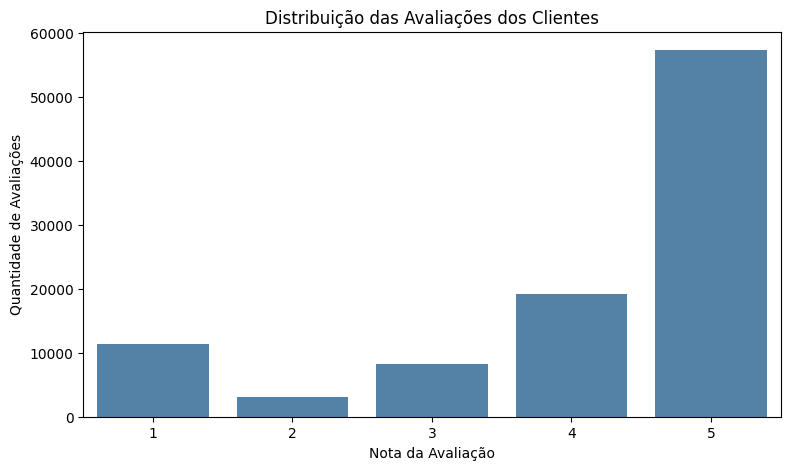

In [202]:
# visualização gráfico distribuição de avaliações

plt.figure(figsize=(9,5))

sns.countplot(
    data=df_reviews,
    x='review_score',
    color='steelblue'
)

plt.title('Distribuição das Avaliações dos Clientes')
plt.xlabel('Nota da Avaliação')
plt.ylabel('Quantidade de Avaliações')

plt.show()

In [203]:
# Nota média
nota_media = df_reviews['review_score'].mean()

# Percentual de avaliações positivas (4 e 5)
avaliacoes_positivas = (
    df_reviews['review_score'].isin([4, 5]).mean() * 100
)

# Percentual de avaliações negativas (1 e 2)
avaliacoes_negativas = (
    df_reviews['review_score'].isin([1, 2]).mean() * 100
)

print(f'Nota média: {nota_media:.2f}')
print(f'Avaliações positivas: {avaliacoes_positivas:.2f}%')
print(f'Avaliações negativas: {avaliacoes_negativas:.2f}%')

Nota média: 4.09
Avaliações positivas: 77.07%
Avaliações negativas: 14.69%


In [204]:
# Verificar comentários preenchidos

df_reviews['review_comment_message'].notna().sum()

np.int64(40977)

In [205]:
import re
import nltk

from nltk.corpus import stopwords
from collections import Counter

nltk.download('stopwords')

# Palavras que não agregam muito significado
stop_words = set(stopwords.words('portuguese'))

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [206]:
def limpar_texto(texto):

    texto = str(texto).lower()

    # Remover números e caracteres especiais
    texto = re.sub(r'[^a-záàâãéèêíïóôõöúçñ ]', '', texto)

    # Separar palavras
    palavras = texto.split()

    # Remover stopwords
    palavras = [
        palavra for palavra in palavras
        if palavra not in stop_words
        and len(palavra) > 2
    ]

    return palavras


# Aplicar limpeza
comentarios = df_reviews[
    'review_comment_message'
].dropna()

palavras = []

for comentario in comentarios:
    palavras.extend(limpar_texto(comentario))

In [207]:
# Contar palavras
frequencia = Counter(palavras)

# 20 palavras mais frequentes
mais_frequentes = frequencia.most_common(20)

df_palavras = pd.DataFrame(
    mais_frequentes,
    columns=['Palavra', 'Frequência']
)

print(df_palavras)

      Palavra  Frequência
0     produto       17979
1       prazo        8131
2     entrega        6311
3       antes        5598
4      chegou        5420
5      recebi        5181
6         bom        4479
7   recomendo        4023
8    entregue        3713
9        veio        3234
10        bem        3071
11    comprei        2695
12  qualidade        2671
13       loja        2330
14       tudo        2282
15      ainda        2281
16     compra        2135
17     gostei        1835
18      ótimo        1770
19  excelente        1735


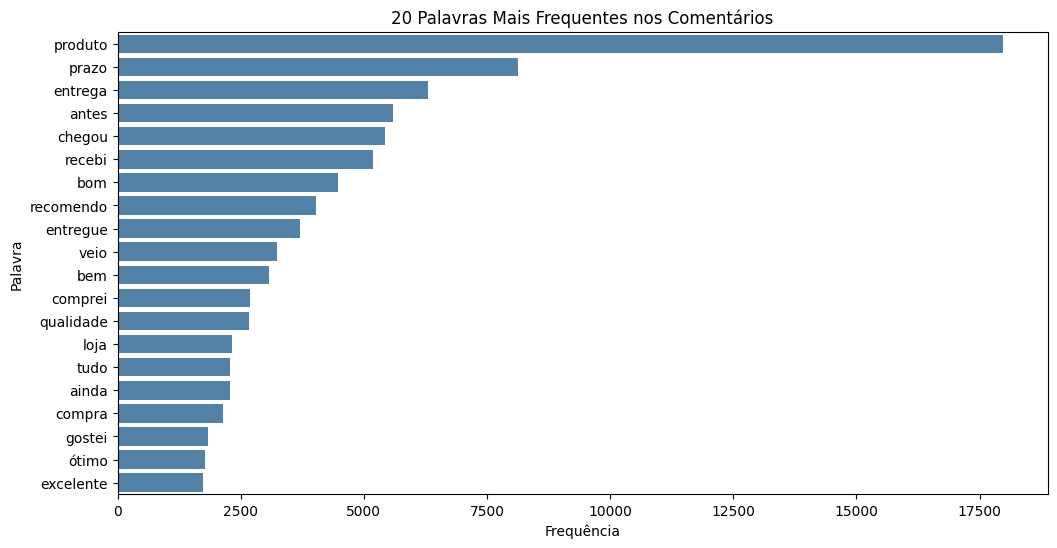

In [208]:
# visualização gráfico palavras mais frequentes

plt.figure(figsize=(12,6))

sns.barplot(
    data=df_palavras,
    x='Frequência',
    y='Palavra',
    color='steelblue'
)

plt.title('20 Palavras Mais Frequentes nos Comentários')
plt.xlabel('Frequência')
plt.ylabel('Palavra')

plt.show()

In [209]:
# Comentários positivos
comentarios_positivos = df_reviews[
    (df_reviews['review_score'].isin([4, 5])) &
    (df_reviews['review_comment_message'].notna())
]

# Comentários negativos
comentarios_negativos = df_reviews[
    (df_reviews['review_score'].isin([1, 2])) &
    (df_reviews['review_comment_message'].notna())
]


In [210]:
def palavras_frequentes(df, coluna, quantidade=15):

    palavras = []

    for comentario in df[coluna]:
        palavras.extend(limpar_texto(comentario))

    frequencia = Counter(palavras)

    return pd.DataFrame(
        frequencia.most_common(quantidade),
        columns=['Palavra', 'Frequência']
    )


# Positivos
freq_positivos = palavras_frequentes(
    comentarios_positivos,
    'review_comment_message'
)

# Negativos
freq_negativos = palavras_frequentes(
    comentarios_negativos,
    'review_comment_message'
)

print('COMENTÁRIOS POSITIVOS')
print(freq_positivos)

print('\nCOMENTÁRIOS NEGATIVOS')
print(freq_negativos)

COMENTÁRIOS POSITIVOS
      Palavra  Frequência
0     produto       10351
1       prazo        6775
2       antes        5255
3     entrega        4460
4      chegou        3914
5         bom        3892
6   recomendo        3570
7         bem        2660
8    entregue        2140
9   qualidade        2091
10       tudo        2048
11      ótimo        1712
12  excelente        1699
13      super        1545
14     recebi        1427

COMENTÁRIOS NEGATIVOS
     Palavra  Frequência
0    produto        6070
1     recebi        3227
2    comprei        1835
3       veio        1530
4    entrega        1376
5      ainda        1371
6   entregue        1290
7     chegou        1157
8        nao         926
9      prazo         890
10    compra         886
11    pedido         773
12      loja         760
13       dia         739
14     agora         678


In [211]:
# bases

df_order_items = pd.read_csv('/content/olist_order_items_dataset.csv')
df_products = pd.read_csv('/content/olist_products_dataset.csv')
df_orders = pd.read_csv('/content/olist_orders_dataset.csv')

In [212]:
# Converter datas para datetime

colunas_data = [
    'order_purchase_timestamp',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]

for coluna in colunas_data:
    df_orders[coluna] = pd.to_datetime(
        df_orders[coluna],
        errors='coerce'
    )

# Garantir que as notas sejam numéricas
df_reviews['review_score'] = pd.to_numeric(
    df_reviews['review_score'],
    errors='coerce'
)

In [213]:
# Resumo financeiro por pedido

df_preco = (
    df_order_items
    .groupby('order_id')
    .agg(
        valor_pedido=('price', 'sum'),
        frete=('freight_value', 'sum'),
        quantidade_itens=('product_id', 'count')
    )
    .reset_index()
)

# Uma nota média por pedido
df_notas = (
    df_reviews
    .groupby('order_id')
    .agg(review_score=('review_score', 'mean'))
    .reset_index()
)

# Consolidar pedidos, notas e valores
df_satisfacao = (
    df_orders
    .merge(df_notas, on='order_id', how='inner')
    .merge(df_preco, on='order_id', how='left')
)

# Considerar somente pedidos entregues
df_satisfacao = df_satisfacao[
    df_satisfacao['order_delivered_customer_date'].notna()
].copy()

In [214]:
# Calcular tempo de entrega em dias

df_satisfacao['tempo_entrega'] = (
    df_satisfacao['order_delivered_customer_date'] -
    df_satisfacao['order_purchase_timestamp']
).dt.total_seconds() / 86400

# Calcular atraso em relação à data estimada

df_satisfacao['dias_atraso'] = (
    df_satisfacao['order_delivered_customer_date'] -
    df_satisfacao['order_estimated_delivery_date']
).dt.total_seconds() / 86400

# Criar classificação de entrega

df_satisfacao['situacao_entrega'] = np.where(
    df_satisfacao['dias_atraso'] <= 0,
    'No prazo',
    'Atrasada'
)

In [215]:
# Nota média por situação de entrega

analise_entrega = (
    df_satisfacao
    .groupby('situacao_entrega')
    .agg(
        nota_media=('review_score', 'mean'),
        quantidade=('order_id', 'count'),
        tempo_medio=('tempo_entrega', 'mean')
    )
    .reset_index()
)

print(analise_entrega)

  situacao_entrega  nota_media  quantidade  tempo_medio
0         Atrasada    2.566562        7662    31.378625
1         No prazo    4.294151       88168    10.878160


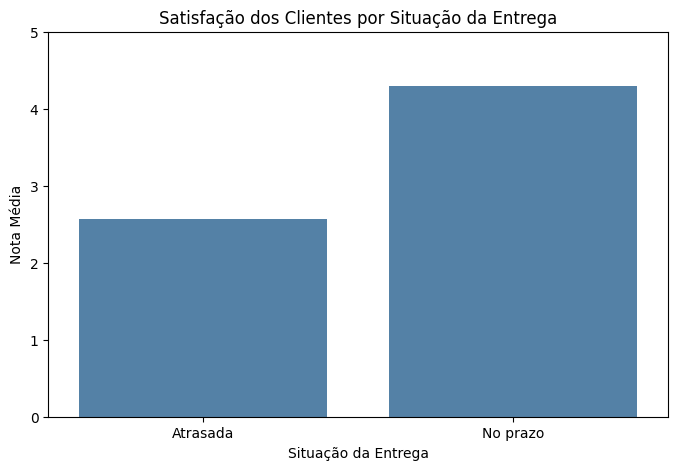

In [216]:
# visualização gráfico

plt.figure(figsize=(8,5))

sns.barplot(
    data=analise_entrega,
    x='situacao_entrega',
    y='nota_media',
    color='steelblue'
)

plt.title('Satisfação dos Clientes por Situação da Entrega')
plt.xlabel('Situação da Entrega')
plt.ylabel('Nota Média')

plt.ylim(0, 5)
plt.show()

In [217]:
correlacao_entrega = df_satisfacao[
    ['tempo_entrega', 'review_score']
].corr()

print(correlacao_entrega)

               tempo_entrega  review_score
tempo_entrega       1.000000     -0.334302
review_score       -0.334302      1.000000


In [218]:
# Verificar relação entre preço e satisfação

analise_preco = (
    df_satisfacao
    .groupby('review_score')
    .agg(
        preco_medio=('valor_pedido', 'mean'),
        quantidade=('order_id', 'count')
    )
    .reset_index()
)

print(analise_preco)

    review_score  preco_medio  quantidade
0       1.000000   165.251823        9316
1       1.500000   166.135000           8
2       2.000000   143.947798        2916
3       2.500000   111.787333          30
4       3.000000   127.483053        7916
5       3.333333    26.000000           1
6       3.500000   127.733478          23
7       4.000000   132.298114       18868
8       4.333333    34.990000           1
9       4.500000    95.721698          53
10      5.000000   134.608653       56698


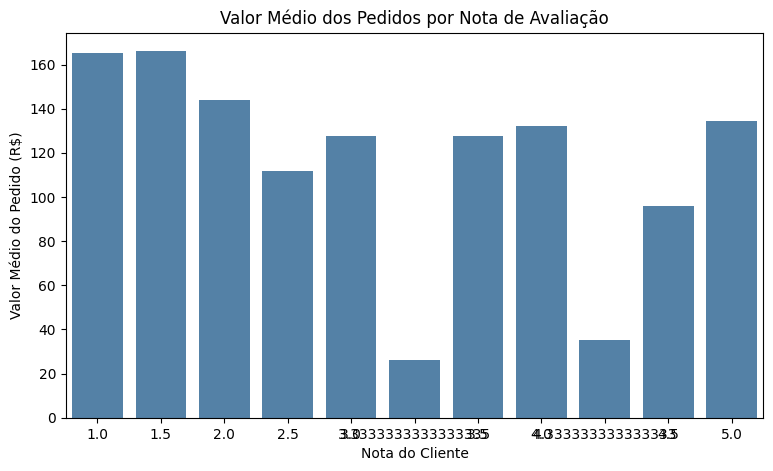

In [219]:
# visualização gráfico

plt.figure(figsize=(9,5))

sns.barplot(
    data=analise_preco,
    x='review_score',
    y='preco_medio',
    color='steelblue'
)

plt.title('Valor Médio dos Pedidos por Nota de Avaliação')
plt.xlabel('Nota do Cliente')
plt.ylabel('Valor Médio do Pedido (R$)')

plt.show()

In [220]:
correlacao_preco = df_satisfacao[
    ['valor_pedido', 'review_score']
].corr()

print(correlacao_preco)

              valor_pedido  review_score
valor_pedido      1.000000     -0.034729
review_score     -0.034729      1.000000


In [221]:
# Criar faixas de preço

df_satisfacao['faixa_preco'] = pd.cut(
    df_satisfacao['valor_pedido'],
    bins=[0, 50, 100, 200, 500, float('inf')],
    labels=[
        'Até R$ 50',
        'R$ 50 a R$ 100',
        'R$ 100 a R$ 200',
        'R$ 200 a R$ 500',
        'Acima de R$ 500'
    ],
    include_lowest=True
)

analise_faixa_preco = (
    df_satisfacao
    .groupby('faixa_preco', observed=False)
    .agg(
        nota_media=('review_score', 'mean'),
        pedidos=('order_id', 'count')
    )
    .reset_index()
)

print(analise_faixa_preco)

       faixa_preco  nota_media  pedidos
0        Até R$ 50    4.217064    28877
1   R$ 50 a R$ 100    4.167997    27435
2  R$ 100 a R$ 200    4.139130    25106
3  R$ 200 a R$ 500    4.042737    10974
4  Acima de R$ 500    4.032723     3438


In [222]:
# Relacionar itens com produtos
df_categoria = df_order_items.merge(
    df_products[
        ['product_id', 'product_category_name']
    ],
    on='product_id',
    how='left'
)

# Relacionar com as avaliações
df_categoria = df_categoria.merge(
    df_notas,
    on='order_id',
    how='inner'
)

# Remover categorias sem identificação
df_categoria = df_categoria.dropna(
    subset=['product_category_name', 'review_score']
)

In [223]:
analise_categoria = (
    df_categoria
    .groupby('product_category_name')
    .agg(
        nota_media=('review_score', 'mean'),
        quantidade_avaliacoes=('order_id', 'nunique'),
        faturamento=('price', 'sum')
    )
    .reset_index()
)

# Categorias com maior número de avaliações
analise_categoria = analise_categoria.sort_values(
    'quantidade_avaliacoes',
    ascending=False
)

print(analise_categoria.head(15))

     product_category_name  nota_media  quantidade_avaliacoes  faturamento
13         cama_mesa_banho    3.898334                   9313   1026192.38
11            beleza_saude    4.141827                   8771   1247947.65
32           esporte_lazer    4.107039                   7669    981241.38
44  informatica_acessorios    3.932601                   6649    906893.17
54        moveis_decoracao    3.907333                   6398    723344.44
72   utilidades_domesticas    4.054785                   5843    627764.28
66      relogios_presentes    4.018855                   5576   1196495.83
70               telefonia    3.945922                   4168    319939.20
8               automotivo    4.064885                   3877    585026.91
12              brinquedos    4.159564                   3853    478878.80
26              cool_stuff    4.146598                   3599    627594.02
40      ferramentas_jardim    4.045539                   3496    481770.90
62              perfumari

In [224]:
# 10 melhores
categorias_validas = analise_categoria[
    analise_categoria['quantidade_avaliacoes'] >= 50
]

melhores_categorias = categorias_validas.nlargest(
    10, 'nota_media'
)

print(melhores_categorias[
    ['product_category_name',
     'nota_media',
     'quantidade_avaliacoes']
])

                 product_category_name  nota_media  quantidade_avaliacoes
48              livros_interesse_geral    4.446266                    508
22  construcao_ferramentas_ferramentas    4.444444                     94
47                   livros_importados    4.400000                     53
49                     livros_tecnicos    4.363636                    257
50                    malas_acessorios    4.315257                   1030
2                    alimentos_bebidas    4.312274                    226
64         portateis_casa_forno_e_cafe    4.302632                     75
34                    fashion_calcados    4.238372                    236
1                            alimentos    4.218182                    445
59                           papelaria    4.195478                   2295


In [225]:
# 10 piores
piores_categorias = categorias_validas.nsmallest(
    10, 'nota_media'
)

print(piores_categorias[
    ['product_category_name',
     'nota_media',
     'quantidade_avaliacoes']
])

               product_category_name  nota_media  quantidade_avaliacoes
55                 moveis_escritorio    3.488968                   1263
38           fashion_roupa_masculina    3.641221                    111
71                    telefonia_fixa    3.681992                    214
7                              audio    3.831944                    347
14                     casa_conforto    3.833333                    395
25  construcao_ferramentas_seguranca    3.844560                    166
13                   cama_mesa_banho    3.898334                   9313
57                       moveis_sala    3.901606                    417
54                  moveis_decoracao    3.907333                   6398
44            informatica_acessorios    3.932601                   6649


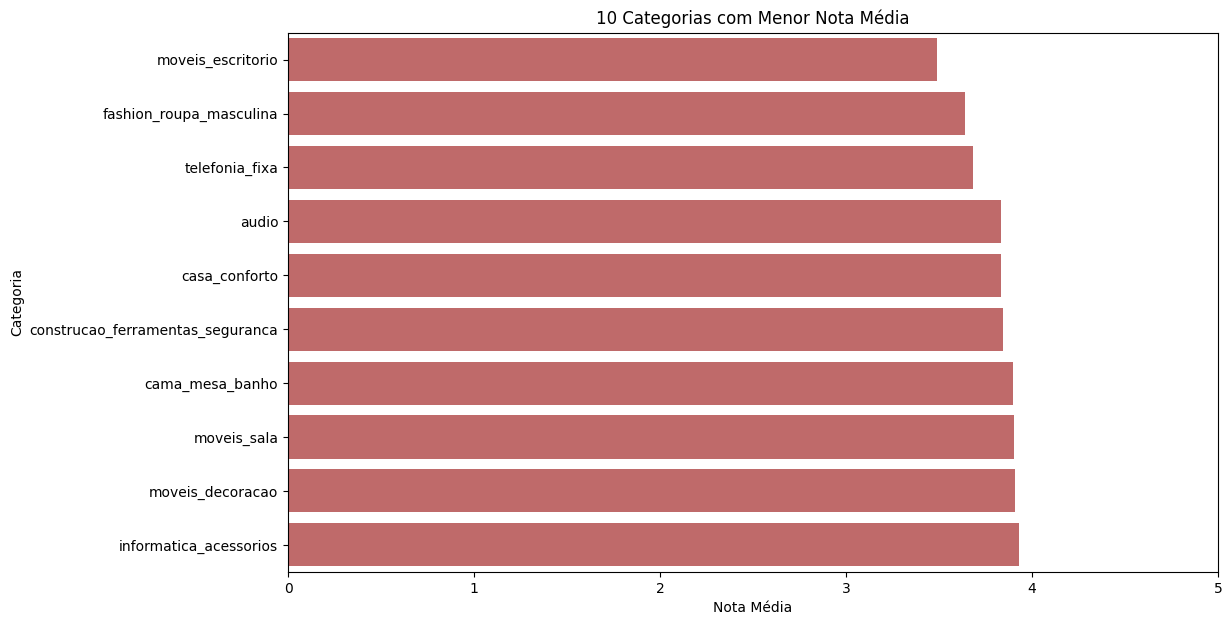

In [226]:
# visualização gráfico

plt.figure(figsize=(12,7))

sns.barplot(
    data=piores_categorias,
    x='nota_media',
    y='product_category_name',
    color='indianred'
)

plt.title('10 Categorias com Menor Nota Média')
plt.xlabel('Nota Média')
plt.ylabel('Categoria')

plt.xlim(0, 5)
plt.show()

In [227]:
# Percentual de avaliações positivas por categoria

df_categoria['avaliacao_positiva'] = (
    df_categoria['review_score'] >= 4
)

satisfacao_categoria = (
    df_categoria
    .drop_duplicates(['order_id', 'product_category_name'])
    .groupby('product_category_name')
    .agg(
        nota_media=('review_score', 'mean'),
        percentual_positivo=('avaliacao_positiva', 'mean'),
        pedidos=('order_id', 'nunique')
    )
    .reset_index()
)

satisfacao_categoria['percentual_positivo'] *= 100

satisfacao_categoria = satisfacao_categoria[
    satisfacao_categoria['pedidos'] >= 50
]

print(
    satisfacao_categoria.sort_values(
        'nota_media',
        ascending=False
    ).head(10)
)

                 product_category_name  nota_media  percentual_positivo  \
48              livros_interesse_geral    4.462598            88.385827   
22  construcao_ferramentas_ferramentas    4.425532            90.425532   
49                     livros_tecnicos    4.400778            86.381323   
2                    alimentos_bebidas    4.382743            83.628319   
50                    malas_acessorios    4.331068            83.980583   
47                   livros_importados    4.320755            83.018868   
64         portateis_casa_forno_e_cafe    4.293333            84.000000   
1                            alimentos    4.276404            83.595506   
59                           papelaria    4.244662            82.091503   
63                            pet_shop    4.238095            81.305115   

    pedidos  
48      508  
22       94  
49      257  
2       226  
50     1030  
47       53  
64       75  
1       445  
59     2295  
63     1701  


In [228]:
# bases

df_customers = pd.read_csv('/content/olist_customers_dataset.csv')

In [229]:
# Converter data de compra

df_orders['order_purchase_timestamp'] = pd.to_datetime(
    df_orders['order_purchase_timestamp'],
    errors='coerce'
)

# Relacionar clientes e pedidos

df_clientes = df_orders.merge(
    df_customers[['customer_id', 'customer_unique_id']],
    on='customer_id',
    how='left'
)

# Considerar pedidos com data de compra válida
df_clientes = df_clientes.dropna(
    subset=['customer_unique_id', 'order_purchase_timestamp']
)

# Considerar pedidos efetivamente concluídos
df_clientes = df_clientes[
    df_clientes['order_status'] == 'delivered'
].copy()

In [230]:
# Data de referência: dia seguinte à última compra da base

data_referencia = (
    df_clientes['order_purchase_timestamp'].max()
    + pd.Timedelta(days=1)
)

print(data_referencia)

2018-08-30 15:00:37


In [231]:
# Última compra por cliente

df_churn = (
    df_clientes
    .groupby('customer_unique_id')
    .agg(
        ultima_compra=('order_purchase_timestamp', 'max'),
        frequencia=('order_id', 'nunique'),
        monetizacao=('order_id', 'count')
    )
    .reset_index()
)

# Calcular recência

df_churn['recencia'] = (
    data_referencia - df_churn['ultima_compra']
).dt.days

print(df_churn.head())

                 customer_unique_id       ultima_compra  frequencia  \
0  0000366f3b9a7992bf8c76cfdf3221e2 2018-05-10 10:56:27           1   
1  0000b849f77a49e4a4ce2b2a4ca5be3f 2018-05-07 11:11:27           1   
2  0000f46a3911fa3c0805444483337064 2017-03-10 21:05:03           1   
3  0000f6ccb0745a6a4b88665a16c9f078 2017-10-12 20:29:41           1   
4  0004aac84e0df4da2b147fca70cf8255 2017-11-14 19:45:42           1   

   monetizacao  recencia  
0            1       112  
1            1       115  
2            1       537  
3            1       321  
4            1       288  


In [232]:
# bases

df_payments = pd.read_csv('/content/olist_order_payments_dataset.csv')

In [233]:
# Somar pagamentos por pedido

df_pagamentos = (
    df_payments
    .groupby('order_id')
    .agg(
        valor_pago=('payment_value', 'sum')
    )
    .reset_index()
)

# Relacionar pagamentos aos pedidos e clientes

df_valor_cliente = (
    df_clientes
    .merge(df_pagamentos, on='order_id', how='left')
)

# Monetização por cliente único

df_monetizacao = (
    df_valor_cliente
    .groupby('customer_unique_id')
    .agg(
        monetizacao=('valor_pago', 'sum')
    )
    .reset_index()
)

# Adicionar monetização à base de churn

df_churn = df_churn.drop(
    columns=['monetizacao'],
    errors='ignore'
)

df_churn = df_churn.merge(
    df_monetizacao,
    on='customer_unique_id',
    how='left'
)

print(df_churn.head())

                 customer_unique_id       ultima_compra  frequencia  recencia  \
0  0000366f3b9a7992bf8c76cfdf3221e2 2018-05-10 10:56:27           1       112   
1  0000b849f77a49e4a4ce2b2a4ca5be3f 2018-05-07 11:11:27           1       115   
2  0000f46a3911fa3c0805444483337064 2017-03-10 21:05:03           1       537   
3  0000f6ccb0745a6a4b88665a16c9f078 2017-10-12 20:29:41           1       321   
4  0004aac84e0df4da2b147fca70cf8255 2017-11-14 19:45:42           1       288   

   monetizacao  
0       141.90  
1        27.19  
2        86.22  
3        43.62  
4       196.89  


In [234]:
def classificar_churn(dias):

    if dias <= 90:
        return 'Ativo'

    elif dias <= 180:
        return 'Atenção'

    elif dias <= 365:
        return 'Alto risco'

    else:
        return 'Churn provável'


df_churn['risco_churn'] = (
    df_churn['recencia'].apply(classificar_churn)
)

print(df_churn.head())

                 customer_unique_id       ultima_compra  frequencia  recencia  \
0  0000366f3b9a7992bf8c76cfdf3221e2 2018-05-10 10:56:27           1       112   
1  0000b849f77a49e4a4ce2b2a4ca5be3f 2018-05-07 11:11:27           1       115   
2  0000f46a3911fa3c0805444483337064 2017-03-10 21:05:03           1       537   
3  0000f6ccb0745a6a4b88665a16c9f078 2017-10-12 20:29:41           1       321   
4  0004aac84e0df4da2b147fca70cf8255 2017-11-14 19:45:42           1       288   

   monetizacao     risco_churn  
0       141.90         Atenção  
1        27.19         Atenção  
2        86.22  Churn provável  
3        43.62      Alto risco  
4       196.89      Alto risco  


In [235]:
# Quantidade de clientes por risco

risco_clientes = (
    df_churn['risco_churn']
    .value_counts()
    .reindex([
        'Ativo',
        'Atenção',
        'Alto risco',
        'Churn provável'
    ])
    .reset_index()
)

risco_clientes.columns = [
    'Classificação',
    'Quantidade'
]

risco_clientes['Percentual'] = (
    risco_clientes['Quantidade'] /
    risco_clientes['Quantidade'].sum()
) * 100

print(risco_clientes)

    Classificação  Quantidade  Percentual
0           Ativo       18459   19.772274
1         Atenção       19647   21.044795
2      Alto risco       34514   36.969515
3  Churn provável       20738   22.213415


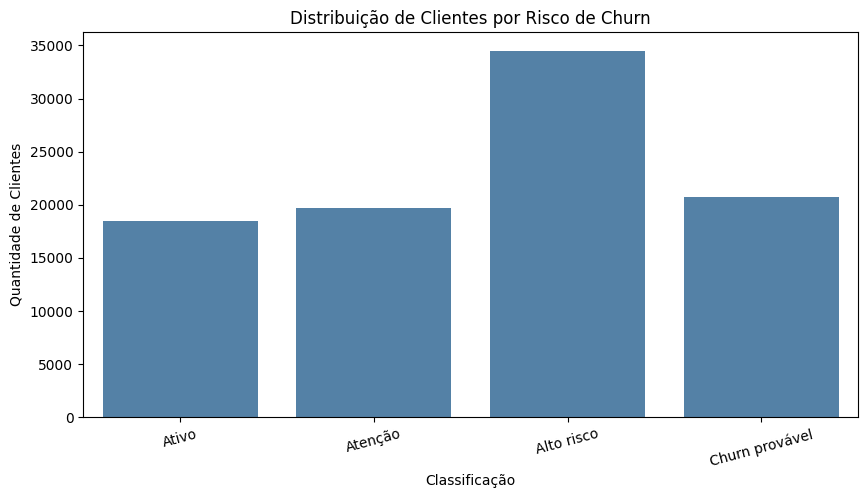

In [236]:
# visualização gráfico

plt.figure(figsize=(10,5))

sns.barplot(
    data=risco_clientes,
    x='Classificação',
    y='Quantidade',
    color='steelblue'
)

plt.title('Distribuição de Clientes por Risco de Churn')
plt.xlabel('Classificação')
plt.ylabel('Quantidade de Clientes')

plt.xticks(rotation=15)
plt.show()

In [237]:
# Clientes em risco

df_clientes_risco = df_churn[
    df_churn['risco_churn'].isin([
        'Alto risco',
        'Churn provável'
    ])
].copy()

# Ordenar pelos clientes que mais gastaram

df_clientes_risco = df_clientes_risco.sort_values(
    'monetizacao',
    ascending=False
)

# Mostrar os 20 clientes de maior valor em risco

print(
    df_clientes_risco[
        [
            'customer_unique_id',
            'recencia',
            'frequencia',
            'monetizacao',
            'risco_churn'
        ]
    ].head(20)
)

                     customer_unique_id  recencia  frequencia  monetizacao  \
3724   0a0a92112bd4c708ca5fde585afaa872       334           1     13664.08   
79636  da122df9eeddfedc1dc1f5349a1a690c       515           2      7571.63   
80463  dc4802a71eae9be1dd28f5d788ceb526       563           1      6929.31   
93081  ff4159b92c40ebe40454e3e6a7c35ed6       462           1      6726.66   
23411  4007669dec559734d6f53e029e360987       279           1      6081.54   
87148  eebb5dda148d3893cdaf5b5ca3040ccb       498           1      4764.34   
86890  edf81e1f3070b9dac83ec83dacdbb9bc       498           1      4194.76   
34543  5e713be0853d8986528d7869a0811d2b       571           1      4042.74   
416    011875f0176909c5cf0b14a9138bb691       529           1      4016.91   
68775  bc5e25094a7d51b6aee35236572e64f4       216           1      3826.80   
34048  5d09b0d82126457e2a8ebfb9c9a1ffc4       566           1      3736.22   
53576  931eabdf0636b8fd60369a8d759917d6       476           1   

In [238]:
# Relacionar pedidos entregues com avaliações

df_reviews_cliente = df_clientes.merge(
    df_reviews[['order_id', 'review_score']],
    on='order_id',
    how='inner'
)

# Nota média por cliente

df_nota_cliente = (
    df_reviews_cliente
    .groupby('customer_unique_id')
    .agg(
        nota_media=('review_score', 'mean')
    )
    .reset_index()
)

# Adicionar nota média à base de churn

df_churn = df_churn.merge(
    df_nota_cliente,
    on='customer_unique_id',
    how='left'
)

In [239]:
analise_satisfacao_churn = (
    df_churn
    .groupby('risco_churn')
    .agg(
        clientes=('customer_unique_id', 'nunique'),
        nota_media=('nota_media', 'mean'),
        monetizacao_media=('monetizacao', 'mean'),
        frequencia_media=('frequencia', 'mean')
    )
    .reset_index()
)

print(analise_satisfacao_churn)

      risco_churn  clientes  nota_media  monetizacao_media  frequencia_media
0      Alto risco     34514    4.064340         162.641135          1.033552
1         Atenção     19647    4.089372         169.954874          1.036087
2           Ativo     18459    4.309186         168.701683          1.038734
3  Churn provável     20738    4.224489         161.823602          1.025943


In [240]:
total_clientes = len(df_churn)

clientes_em_risco = df_churn[
    df_churn['risco_churn'].isin([
        'Alto risco',
        'Churn provável'
    ])
]

quantidade_risco = len(clientes_em_risco)

percentual_risco = (
    quantidade_risco / total_clientes
) * 100

print(f'Total de clientes: {total_clientes}')

print(f'Clientes em risco: {quantidade_risco}')

print(f'Percentual em risco: {percentual_risco:.2f}%')

Total de clientes: 93358
Clientes em risco: 55252
Percentual em risco: 59.18%


In [241]:
faturamento_total = df_churn['monetizacao'].sum()

faturamento_risco = clientes_em_risco[
    'monetizacao'
].sum()

percentual_faturamento_risco = (
    faturamento_risco / faturamento_total
) * 100

print(
    f'Faturamento histórico dos clientes em risco: '
    f'R$ {faturamento_risco:,.2f}'
)

print(
    f'Participação no faturamento: '
    f'{percentual_faturamento_risco:.2f}%'
)

Faturamento histórico dos clientes em risco: R$ 8,969,294.00
Participação no faturamento: 58.16%
